# 1. Datos y preprocesamiento

**Pronóstico del consumo eléctrico residencial por distrito con aprendizaje automático** · Sistemas Inteligentes · Grupo 6 · UNMSM

**Objetivo.** Describir los datos abiertos de ENOSA, revisar su calidad y transformarlos en el panel distrito-mes con el que se entrenan los modelos, sin usar datos personales.

| | |
|---|---|
| **Entradas** | `datos/limpios/enosa_AAAAMM.parquet` (34 meses, solo columnas no personales; se obtienen con `python cli.py descargar`) |
| **Salidas** | `datos/procesados/panel.parquet` y `datos/procesados/preprocesamiento.json` |

### Índice

1. [Configuración](#configuración)
2. [Fuente de los datos](#fuente-de-los-datos)
3. [Variables y datos personales](#variables-y-datos-personales)
4. [Calidad de los datos](#calidad-de-los-datos)
5. [Análisis exploratorio](#análisis-exploratorio)
6. [Limpieza y filtrado](#limpieza-y-filtrado)
7. [Valores atípicos: cercas de Tukey](#valores-atípicos-cercas-de-tukey)
8. [Agregación por distrito y mes](#agregación-por-distrito-y-mes)
9. [La variable objetivo: ¿nivel o variación?](#la-variable-objetivo-nivel-o-variación)
10. [Verificación con el informe](#verificación-con-el-informe)
11. [Conclusiones](#conclusiones)
12. [Referencias](#referencias)

<a id="configuración"></a>

## 1. Configuración

Importaciones, estilo de los gráficos, versiones de las bibliotecas y semilla (para que el notebook sea reproducible) y resultados publicados del informe, que se usan al final para verificar que el notebook obtiene las mismas cifras.

In [1]:
import importlib
import json
import time
import warnings

import estilo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from estilo import BLUE, CYAN, EJE_COMA, GRIS, ICE, MESES, NAVY, coma

from ml import config

estilo.aplicar()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
INFORME = json.loads(config.RESULTADOS.read_text(encoding="utf8"))  # resultados publicados
RESUMEN = json.loads(config.RESUMEN_PREPROCESAMIENTO.read_text(encoding="utf8"))
INICIO = time.time()
MODULOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "sklearn",
    "scipy": "scipy",
    "xgboost": "xgboost",
    "matplotlib": "matplotlib",
}
VERSIONES = {n: importlib.import_module(m).__version__ for n, m in MODULOS.items()}
print("Semilla:", config.SEMILLA)
print(" · ".join(f"{n} {v}" for n, v in VERSIONES.items()))

from ml.config import PERSONALES
from ml.preprocesamiento import RIC_TUKEY, cargar_limpios, construir_panel

Semilla: 42
numpy 2.4.6 · pandas 3.1.1 · scikit-learn 1.9.1 · scipy 1.17.1 · xgboost 3.2.0 · matplotlib 3.11.2


<a id="fuente-de-los-datos"></a>

## 2. Fuente de los datos

El conjunto de datos *Consumo energético de clientes Enosa [Distriluz - DLZ]* se publica en la Plataforma Nacional de Datos Abiertos bajo la licencia **ODbL** (ENOSA, 2026). Cada archivo mensual tiene un registro por suministro: ubicación, tarifa, tipo de cliente, fechas del periodo facturado, importe y consumo. Se usan los 34 meses publicados, de enero de 2024 a octubre de 2026.

Los archivos no tienen formato uniforme (CSV, XLSX o ZIP; algunos CSV sin fila de encabezado), por eso el módulo `ml/fuente.py` asigna las columnas por su **posición** en el diccionario de datos. Aquí se parte de los archivos ya leídos y guardados en Parquet.

In [2]:
df = cargar_limpios(config.DIR_LIMPIOS)
por_mes = df.groupby("PERIODO").size()
print(
    f"{coma(len(df))} registros en {por_mes.size} meses ({por_mes.index[0]} a {por_mes.index[-1]})"
)
anios = por_mes.groupby(por_mes.index.str[:4])
anios.agg(meses="size", registros="sum", promedio_mensual="mean").round(0)

19 713 482 registros en 53 meses ( a S018-07637634)


,meses,registros,promedio_mensual
PERIODO,,,
,1,12,12.0000
11.1,1,1,1.0000
114,1,1,1.0000
202,1,1,1.0000
2023,1,1,1.0000
2024,14,6799024,"485,645.0000"
2025,12,6961778,"580,148.0000"
2026,10,5952612,"595,261.0000"
37,1,1,1.0000


<a id="variables-y-datos-personales"></a>

## 3. Variables y datos personales

El diccionario describe **25 variables**. Las columnas 2 a 6 identifican a la persona (número de suministro, nombre, dirección, tipo y número de documento). Seis meses se publicaron **sin anonimizar**; por eso esas columnas se descartan por posición al leer cada línea y nunca se guardan, en concordancia con la Ley N.° 29733 de Protección de Datos Personales (Congreso de la República del Perú, 2011).

La tabla clasifica las 16 columnas que sí se conservan según su naturaleza y su uso en el trabajo.

In [3]:
assert not set(PERSONALES) & set(df.columns), "ninguna columna personal llega a este notebook"
tipos = {
    "PERIODO": ("Temporal (aaaamm)", "Mes del año y agregación"),
    "FECHA_CORTE": ("Fecha", "No se usa"),
    "ID_UUNN": ("Categórica nominal", "No se usa"),
    "UNIDAD_NEGOCIO": ("Categórica nominal", "Descripción"),
    "TARIFA": ("Categórica nominal", "Filtro (BT5B)"),
    "DEPARTAMENTO": ("Categórica nominal", "Filtro (Piura y Tumbes)"),
    "PROVINCIA": ("Categórica nominal", "Variable de entrada"),
    "DISTRITO": ("Categórica nominal", "Nombre del distrito"),
    "UBIGEO": ("Código geográfico (INEI)", "Clave de agregación"),
    "CARTERA": ("Categórica nominal", "Filtro (residencial)"),
    "FECHA_EMISION": ("Fecha", "No se usa"),
    "FECHA_VENCIMIENTO": ("Fecha", "No se usa"),
    "FECHA_CONSUMO_DESDE": ("Fecha", "Días facturados"),
    "FECHA_CONSUMO_HASTA": ("Fecha", "Días facturados"),
    "IMPORTE": ("Numérica continua (S/)", "Descripción"),
    "CONSUMO": ("Numérica continua (kWh)", "Variable objetivo (agregada)"),
}
pd.DataFrame(
    [(c, str(df[c].dtype), *tipos[c]) for c in df.columns],
    columns=["columna", "tipo en pandas", "naturaleza", "uso"],
).set_index("columna")

,tipo en pandas,naturaleza,uso
columna,,,
PERIODO,str,Temporal (aaaamm),Mes del año y agregación
FECHA_CORTE,str,Fecha,No se usa
ID_UUNN,str,Categórica nominal,No se usa
UNIDAD_NEGOCIO,str,Categórica nominal,Descripción
TARIFA,str,Categórica nominal,Filtro (BT5B)
DEPARTAMENTO,str,Categórica nominal,Filtro (Piura y Tumbes)
PROVINCIA,str,Categórica nominal,Variable de entrada
DISTRITO,str,Categórica nominal,Nombre del distrito
UBIGEO,str,Código geográfico (INEI),Clave de agregación


<a id="calidad-de-los-datos"></a>

## 4. Calidad de los datos

Antes de filtrar se revisan los valores faltantes y las filas repetidas.

- **Faltantes:** se cuentan por columna. Las filas sin periodo, ubigeo, tarifa o consumo no pueden usarse y se descartan en el filtrado.
- **Filas idénticas:** sin el número de suministro (descartado por privacidad), dos hogares distintos del mismo distrito pueden tener exactamente las mismas columnas: mismas fechas de facturación, tarifa y consumo. Por eso una fila repetida **no** indica un registro duplicado y no se elimina; hacerlo borraría hogares reales.

In [4]:
faltantes = df.isna().sum()
display(pd.DataFrame({"faltantes": faltantes, "%": faltantes / len(df) * 100}).T.round(5))
repetidas = pd.util.hash_pandas_object(df, index=False).duplicated()
pct_rep = coma(repetidas.mean() * 100, 1)
print(f"Filas idénticas a otra en las 16 columnas: {coma(repetidas.sum())} ({pct_rep} %)")
ceros = (df["CONSUMO"] == 0) & repetidas
pct_cero = coma(ceros.sum() / repetidas.sum() * 100, 1)
print(f"  de ellas, con consumo cero: {coma(ceros.sum())} ({pct_cero} %)")

,PERIODO,FECHA_CORTE,ID_UUNN,UNIDAD_NEGOCIO,TARIFA,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,CARTERA,FECHA_EMISION,FECHA_VENCIMIENTO,FECHA_CONSUMO_DESDE,FECHA_CONSUMO_HASTA,IMPORTE,CONSUMO
faltantes,39.0000,3.0000,39.0000,39.0000,44.0000,45.0000,45.0000,45.0000,45.0000,50.0000,51.0000,51.0000,51.0000,52.0000,70.0000,70.0000
%,0.0002,0.0000,0.0002,0.0002,0.0002,0.0002,0.0002,0.0002,0.0002,0.0003,0.0003,0.0003,0.0003,0.0003,0.0004,0.0004


Filas idénticas a otra en las 16 columnas: 8 544 119 (43,3 %)
  de ellas, con consumo cero: 1 393 059 (16,3 %)


Hay muy pocos faltantes (decenas de filas en 19,7 millones), en registros mal formados que el filtrado descarta. Las filas idénticas son frecuentes (43 %) porque, dentro de un distrito, los hogares comparten fechas de facturación, tarifa y fecha de corte, y es común que registren el mismo consumo en kWh; solo el 16 % de ellas tiene consumo cero. Como no hay forma de distinguirlas de hogares distintos, se conservan.

<a id="análisis-exploratorio"></a>

## 5. Análisis exploratorio

Se describe el consumo de un recibo residencial con tarifa BT5B (los hogares), junto con el importe y los días facturados. El consumo tiene una **cola larga a la derecha** y muchos recibos en cero, por lo que el análisis trabaja con suministros activos y trata los valores extremos.

In [5]:
hog = df[(df["CARTERA"] == "C") & (df["TARIFA"] == "BT5B")]
dias_hog = (
    pd.to_datetime(hog["FECHA_CONSUMO_HASTA"], format="%Y%m%d", errors="coerce")
    - pd.to_datetime(hog["FECHA_CONSUMO_DESDE"], format="%Y%m%d", errors="coerce")
).dt.days
desc = pd.DataFrame(
    {"consumo (kWh)": hog["CONSUMO"], "importe (S/)": hog["IMPORTE"], "días facturados": dias_hog}
)
desc.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max
consumo (kWh),"19,508,196.0000",93.4300,260.7900,0.0000,14.0000,50.0000,100.0000,265.0000,806.0000,"52,899.0000"
importe (S/),"19,508,196.0000",87.8000,239.9200,"-3,343.9000",13.5000,44.6000,91.8000,253.6000,760.6000,"91,232.3000"
días facturados,"19,508,196.0000",29.4400,0.9400,27.0000,29.0000,30.0000,30.0000,31.0000,31.0000,32.0000


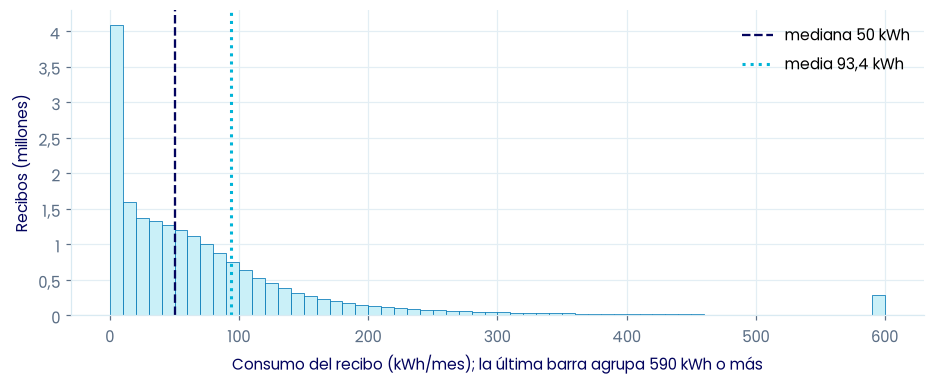

Recibos en cero: 8,9 %


In [6]:
res = hog["CONSUMO"].dropna()
fig, ax = plt.subplots()
ax.hist(
    res.clip(upper=600),
    bins=60,
    range=(0, 600),
    color=ICE,
    edgecolor=BLUE,
    lw=0.5,
    weights=np.full(len(res), 1e-6),
)
ax.axvline(res.median(), color=NAVY, ls="--", label=f"mediana {coma(res.median())} kWh")
ax.axvline(res.mean(), color=CYAN, ls=":", lw=2, label=f"media {coma(res.mean(), 1)} kWh")
ax.set(
    xlabel="Consumo del recibo (kWh/mes); la última barra agrupa 590 kWh o más",
    ylabel="Recibos (millones)",
)
ax.yaxis.set_major_formatter(EJE_COMA)
ax.legend()
plt.show()
print(f"Recibos en cero: {coma((res == 0).mean() * 100, 1)} %")

La mediana (50 kWh) está muy por debajo de la media (unos 93 kWh): unos pocos recibos muy altos arrastran el promedio. Cerca del 9 % de los recibos registra consumo cero y los días facturados van de 27 a 32. El importe tiene algunos valores negativos; como no se usa en los modelos, no se trata.

<a id="limpieza-y-filtrado"></a>

## 6. Limpieza y filtrado

Los filtros, en orden:

1. registros con periodo, ubigeo y departamento válidos (Piura o Tumbes);
2. clientes residenciales (cartera común, `C`) con tarifa **BT5B**;
3. consumo no nulo ni negativo y periodo facturado de 20 a 40 días.

In [7]:
ok = (
    df["PERIODO"].str.fullmatch(r"202[4-6](0[1-9]|1[0-2])", na=False)
    & df["UBIGEO"].str.fullmatch(r"(20|24)\d{4}", na=False)
    & df["DEPARTAMENTO"].str.upper().str.strip().isin(["PIURA", "TUMBES"])
)
paso1 = df[ok]
paso2 = paso1[(paso1["CARTERA"] == "C") & (paso1["TARIFA"] == "BT5B")]
dias = (
    pd.to_datetime(paso2["FECHA_CONSUMO_HASTA"], format="%Y%m%d", errors="coerce")
    - pd.to_datetime(paso2["FECHA_CONSUMO_DESDE"], format="%Y%m%d", errors="coerce")
).dt.days
paso3 = paso2[paso2["CONSUMO"].notna() & (paso2["CONSUMO"] >= 0) & dias.between(20, 40)]
pasos = [
    "Descargados",
    "Periodo, ubigeo y departamento válidos",
    "Residenciales BT5B",
    "Consumo y días válidos",
]
pd.DataFrame({"registros": [len(df), len(paso1), len(paso2), len(paso3)]}, index=pasos)

,registros
Descargados,19713482
"Periodo, ubigeo y departamento válidos",19700503
Residenciales BT5B,19495985
Consumo y días válidos,19495985


No hubo consumos nulos o negativos ni periodos inválidos entre los hogares BT5B: el último paso no elimina registros.

<a id="valores-atípicos-cercas-de-tukey"></a>

## 7. Valores atípicos: cercas de Tukey

Sobre el **logaritmo** del consumo de los suministros activos (consumo > 0) se aplican las cercas de Tukey con un factor de 3 veces el rango intercuartílico (Tukey, 1977):

$$\ln(x) < Q_1 - 3\,\mathrm{RIC} \quad \text{o} \quad \ln(x) > Q_3 + 3\,\mathrm{RIC}$$

¿Por qué así? El consumo es muy asimétrico: aplicadas sobre los kWh, las cercas cortarían consumos altos pero plausibles. En logaritmo la distribución es casi simétrica, y el factor 3 (en vez del 1,5 habitual) solo descarta valores extremos.

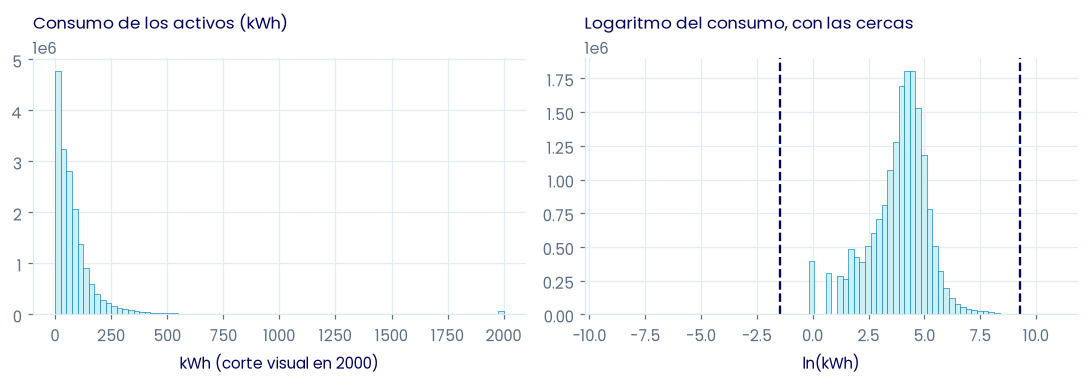

Límites: 0,23 kWh y 10 773 kWh
Atípicos por encima: 628 · por debajo: 579
Recibos activos limpios: 17 766 272


In [8]:
act = paso3[paso3["CONSUMO"] > 0]
lg = np.log(act["CONSUMO"])
q1, q3 = lg.quantile([0.25, 0.75])
inf, sup = q1 - RIC_TUKEY * (q3 - q1), q3 + RIC_TUKEY * (q3 - q1)
fig, (a1, a2) = plt.subplots(1, 2)
a1.hist(act["CONSUMO"].clip(upper=2000), bins=80, color=ICE, edgecolor=BLUE, lw=0.4)
a1.set(title="Consumo de los activos (kWh)", xlabel="kWh (corte visual en 2000)")
a2.hist(lg, bins=80, color=ICE, edgecolor=BLUE, lw=0.4)
for v in (inf, sup):
    a2.axvline(v, color=NAVY, ls="--")
a2.set(title="Logaritmo del consumo, con las cercas", xlabel="ln(kWh)")
plt.tight_layout()
plt.show()
print(f"Límites: {coma(np.exp(inf), 2)} kWh y {coma(np.exp(sup))} kWh")
n_sup, n_inf = (lg > sup).sum(), (lg < inf).sum()
print(f"Atípicos por encima: {n_sup} · por debajo: {n_inf}")
print(f"Recibos activos limpios: {coma(len(lg) - n_sup - n_inf)}")

A la izquierda la cola larga impide ver la forma; a la derecha, en logaritmo, la distribución es casi simétrica y las cercas quedan en los extremos. Se excluyen 628 recibos por encima y 579 por debajo, menos del 0,01 % de los activos. Los recibos en cero no se eliminan: alimentan la proporción de recibos en cero de cada distrito.

<a id="agregación-por-distrito-y-mes"></a>

## 8. Agregación por distrito y mes

La unidad de análisis es el **distrito en un mes**, porque los datos no identifican al mismo hogar de un mes a otro. La variable objetivo es el consumo medio de los suministros activos:

$$y_{d,t} = \frac{1}{n_{d,t}} \sum_{j=1}^{n_{d,t}} \mathrm{consumo}_{j}$$

Junto con ella se guardan el número de suministros, la proporción de recibos en cero y los días facturados promedio. La función `construir_panel` aplica todos los pasos anteriores y la agregación; abajo se comprueba que su consumo medio coincide con el cálculo directo.

In [9]:
panel, resumen = construir_panel(df)
limpios = act[(lg <= sup) & (lg >= inf)]
y_directo = limpios.groupby(["UBIGEO", "PERIODO"])["CONSUMO"].mean()
y_panel = panel.set_index(["UBIGEO", "PERIODO"])["y"].sort_index()
assert np.allclose(y_directo.sort_index().values, y_panel.values)
del df, hog, desc, res, paso1, paso2, paso3, act, lg, limpios  # libera memoria (unos 4 GB)
n_d, n_m = panel["UBIGEO"].nunique(), panel["PERIODO"].nunique()
print(f"Panel: {n_d} distritos × {n_m} meses = {len(panel)} filas")
print("Sin faltantes en la variable objetivo:", panel["y"].notna().all())
cols = ["UBIGEO", "DIST_N", "PROV_N", "PERIODO", "y", "mediana", "n_sum", "n_act", "p_cero", "dias"]
panel[cols].head()

Panel: 78 distritos × 34 meses = 2652 filas
Sin faltantes en la variable objetivo: True


,UBIGEO,DIST_N,PROV_N,PERIODO,y,mediana,n_sum,n_act,p_cero,dias
0,200101,PIURA,PIURA,202401,164.6795,100.0000,82413,77569,0.0587,29.4666
1,200101,PIURA,PIURA,202402,173.9723,104.0000,83243,78209,0.0603,28.0873
2,200101,PIURA,PIURA,202403,189.7224,113.0000,83017,77949,0.0608,30.4646
3,200101,PIURA,PIURA,202404,178.4769,105.0000,82874,77763,0.0615,29.4302
4,200101,PIURA,PIURA,202405,162.8210,98.0000,83188,77833,0.0641,30.2870


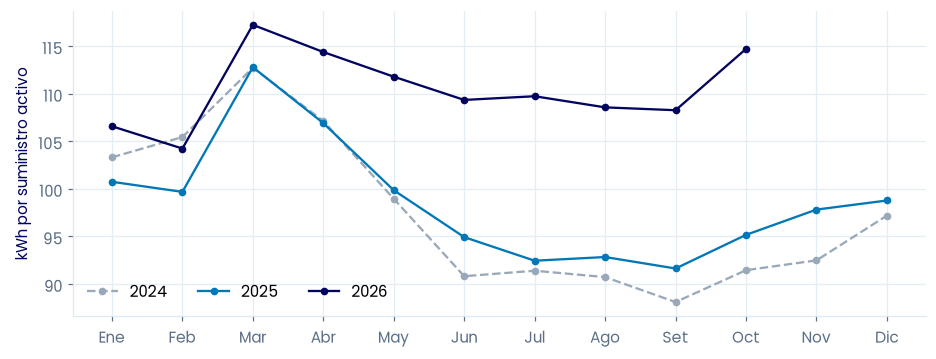

In [10]:
sr = panel.assign(kwh=panel["y"] * panel["n_act"]).groupby("PERIODO")[["kwh", "n_act"]].sum()
media = sr["kwh"] / sr["n_act"]
fig, ax = plt.subplots()
for anio, col, ls in (("2024", GRIS, "--"), ("2025", BLUE, "-"), ("2026", NAVY, "-")):
    m = media[media.index.str.startswith(anio)]
    ax.plot(
        [int(p[4:]) - 1 for p in m.index], m.values, color=col, ls=ls, marker="o", ms=4, label=anio
    )
ax.set_xticks(range(12), MESES)
ax.set_ylabel("kWh por suministro activo")
ax.legend(ncol=3)
plt.show()

El consumo medio regional tiene su máximo en marzo (verano) y, en 2026, fue mayor que en el mismo mes de 2025 en todos los meses. Este cambio de nivel es la clave de la siguiente sección.

<a id="la-variable-objetivo-nivel-o-variación"></a>

## 9. La variable objetivo: ¿nivel o variación?

Hay dos formas de plantear el objetivo:

- **Corrida 1 (nivel):** pronosticar $y_t$ con $y_{t-1}, y_{t-2}, y_{t-12}$, los días facturados, el logaritmo del número de suministros y la proporción de recibos en cero del mes anterior.
- **Corrida 2 (variación):** pronosticar $\Delta_t = \ln(y_t / y_{t-1})$ con $\Delta_{t-1}$, $\Delta_{t-12}$ y la razón de días facturados; el consumo se recupera como $\hat y_t = y_{t-1}\,e^{\hat\Delta_t}$.

En ambas, el mes, la provincia y el grupo de k-means son variables categóricas. Como $\Delta_{t-12}$ necesita el consumo de 13 meses antes, las filas supervisadas empiezan en febrero de 2025. Los gráficos comparan ambas variables objetivo.

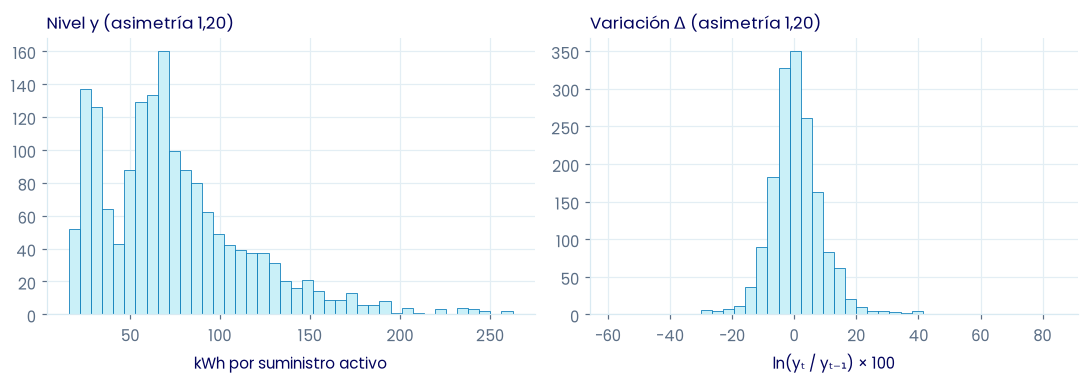

Filas supervisadas: 1638 (202502 a 202610)
Corrida 1: ['lag1', 'lag2', 'lag12', 'dias', 'log_n', 'p_cero_lag1', 'mes', 'PROV_N', 'grupo'] → y
Corrida 2: ['dl_prev', 'dl_seas', 'dias_ratio', 'log_n', 'p_cero_lag1', 'mes', 'PROV_N', 'grupo'] → dl


In [11]:
from scipy.stats import skew

from ml import caracteristicas as car

pn = car.agregar_rezagos(
    car.ordenar(panel).assign(grupo=0)
)  # el grupo real se añade en el notebook 3
sup_ = car.supervisado(pn)
fig, (a1, a2) = plt.subplots(1, 2)
a1.hist(sup_["y"], bins=40, color=ICE, edgecolor=BLUE, lw=0.5)
a1.set(title=f"Nivel y (asimetría {coma(skew(sup_['y']), 2)})", xlabel="kWh por suministro activo")
a2.hist(sup_["dl"] * 100, bins=40, color=ICE, edgecolor=BLUE, lw=0.5)
a2.set(title=f"Variación Δ (asimetría {coma(skew(sup_['dl']), 2)})", xlabel="ln(yₜ / yₜ₋₁) × 100")
plt.tight_layout()
plt.show()
print(f"Filas supervisadas: {len(sup_)} ({sup_['PERIODO'].min()} a {sup_['PERIODO'].max()})")
print("Corrida 1:", car.entradas(1), "→", car.objetivo(1))
print("Corrida 2:", car.entradas(2), "→", car.objetivo(2))

El **nivel** va de unos 20 a más de 200 kWh según el distrito: un modelo que lo pronostique tiene que aprender el nivel de cada uno y queda expuesto a cambios de nivel como el de 2026. La **variación** está centrada en cero y es comparable entre distritos: el pronóstico parte siempre del último consumo observado. El notebook 3 muestra que esta elección es la que decide el resultado.

<a id="verificación-con-el-informe"></a>

## 10. Verificación con el informe

El panel y los conteos obtenidos aquí deben coincidir exactamente con los archivos publicados en el repositorio, que son los del informe.

In [12]:
publicado = pd.read_parquet(config.PANEL).reset_index(drop=True)
pd.testing.assert_frame_equal(panel.reset_index(drop=True), publicado)
claves = (
    "filas_totales",
    "residenciales_bt5b",
    "atipicos_sup",
    "atipicos_inf",
    "activos_limpios",
    "celdas_total",
)
for clave in claves:
    assert resumen[clave] == RESUMEN[clave], clave
print("El panel y los conteos coinciden con los publicados.")

print(f"Tiempo de ejecución del notebook: {time.time() - INICIO:.0f} s")

El panel y los conteos coinciden con los publicados.
Tiempo de ejecución del notebook: 113 s


<a id="conclusiones"></a>

## 11. Conclusiones

- Los 19,7 millones de registros se reducen a **17 766 272 recibos activos limpios** de hogares BT5B y se agregan en un panel completo de **78 distritos × 34 meses** (2652 filas), sin usar ninguna columna personal.
- Los faltantes son mínimos y las filas idénticas se explican por la anonimización, no por registros duplicados.
- El consumo tiene cola larga y muchos ceros; las cercas de Tukey sobre el logaritmo eliminan solo valores extremos.
- La serie regional es estacional y en 2026 cambió de nivel, lo que motiva pronosticar la **variación mensual** en lugar del nivel.

El panel resultante es la entrada de los notebooks 2 (no supervisado) y 3 (supervisado).

<a id="referencias"></a>

## 12. Referencias

- Congreso de la República del Perú. (2011, 3 de julio). *Ley N.° 29733, Ley de Protección de Datos Personales*. Diario Oficial El Peruano. https://diariooficial.elperuano.pe/Normas/obtenerDocumento?idNorma=23
- Empresa Regional de Servicio Público de Electricidad Electronoroeste S.A. - ENOSA. (2026). *Consumo energético de clientes Enosa [Distriluz - DLZ]* [Conjunto de datos]. Plataforma Nacional de Datos Abiertos. Recuperado el 20 de noviembre de 2026, de https://www.datosabiertos.gob.pe/dataset/consumo-energ%C3%A9tico-de-clientes-enosa-distriluz-dlz
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.